# Statistical robustness of extreme tail-latency percentiles (p99.9 / p99.99)

**Why this notebook exists:** a reviewer flagged that the extreme-tail percentile
figures in `00_tail_latency.ipynb` (per-provider p99.9 / p99.99 tail factors) are
reported as single point estimates with no indication of how many raw
observations actually back them, no confidence intervals, and no check for
whether the headline "provider A vs provider B" comparisons survive small
perturbations of the tail. This notebook adds that robustness layer.

**Scope / how this mirrors the existing pipeline:** this notebook reuses the
*exact* filtering logic already used for the per-provider warmstart figures in
`00_tail_latency.ipynb` (cells 1 & 3):

- `experiment = 'warmstart'`
- `cold_starts = 0` for every provider **except** `fastly`, which has no
  `cold_starts` column populated for warmstart and is therefore left
  unfiltered (same special case as the existing notebook).
- Same 9 providers: `google, awsX86, awsARM, oracleX86, oracleARM, deno,
  cloudflare, flyio, fastly`.
- Same source database (`../data.db`), read as
  **raw per-request** `http_req_waiting` values (not pre-aggregated) — this
  was confirmed available (38M rows, per-request granularity) so no
  regeneration from logs was needed.
- `awsEC2` / the 1-week tail baseline DB is **out of scope** here per
  explicit instruction — only the main per-provider database is covered.

This notebook does **not** modify or delete any cells in `00_tail_latency.ipynb`
— it is purely additive, in its own file, and every analysis below lives in
its own cell so it can be dropped into the paper pipeline independently.

**What's covered (matches the reviewer's ask 1:1):**

1. Effective sample size (`N_eff = N * (1-p)`) for every p99.9 / p99.99 claim, with a `< 30` low-confidence flag.
2. 95% CIs for p99.9 / p99.99 via (a) nonparametric bootstrap resampling and (b) the binomial order-statistic method, as error bars on a per-provider plot.
3. Sensitivity analysis: leave-top-k-out, per-day/window spread, exact-vs-interpolated percentile definition ("sketch" stand-in — see note in that cell), and include/exclude-failed-requests.
4. A single combined table: N, N_eff, point estimate, and both 95% CIs for p99.9 and p99.99, per provider.


In [1]:

import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")

# Reuses the same DB path convention as 00_tail_latency.ipynb.
cnx = sqlite3.connect("../data.db")

# Same provider list as 00_tail_latency.ipynb (cells 1 & 3), awsEC2 excluded
# (out of scope for this notebook per instruction).
PROVIDERS = [
    "google", "awsX86", "awsARM", "oracleX86", "oracleARM",
    "deno", "cloudflare", "flyio", "fastly",
]

PERCENTILES = {"p99.9": 0.999, "p99.99": 0.9999}

# Reproducible bootstrap draws.
RNG_SEED = 42


## 1. Load raw per-request latencies (mirrors existing warmstart filter exactly)

Same query shape as `00_tail_latency.ipynb` cells 1/3: `fastly` gets no
`cold_starts` filter, every other provider gets `AND cold_starts = 0`. We
additionally pull `http_req_failed` and `date_time` here (not in the original
query) because they're needed for the sensitivity checks in section 5 — the
core `http_req_waiting` column and filter predicate are unchanged.

In [2]:

def load_provider_raw(provider: str) -> pd.DataFrame:
    if provider == "fastly":
        query = """
            SELECT date_time, http_req_waiting, http_req_failed
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
    else:
        query = """
            SELECT date_time, http_req_waiting, http_req_failed
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
    df = pd.read_sql_query(query, cnx, params=[provider])
    df = df.dropna(subset=["http_req_waiting"])
    return df

provider_data: dict[str, pd.DataFrame] = {}
for provider in PROVIDERS:
    df = load_provider_raw(provider)
    provider_data[provider] = df
    print(f"{provider:12s}  N = {len(df):>9,d}")


google        N = 1,919,360


awsX86        N = 1,618,744


awsARM        N = 1,915,505


oracleX86     N = 1,848,286


oracleARM     N = 1,886,056


deno          N =   293,184


cloudflare    N =   278,482


flyio         N = 1,873,525


fastly        N =   640,156


## 2. Effective sample size (N_eff) per percentile claim

`N_eff = N * (1 - p)` is the count of raw observations at or beyond the
percentile cutoff — i.e. how many data points the extreme-tail estimate is
actually resting on. Anything below ~30 is flagged as low-confidence: below
that, a single extra/missing sample can move the reported percentile by a
visible amount, and normal-approximation-based reasoning about it stops being
reliable.

In [3]:

LOW_CONFIDENCE_THRESHOLD = 30

neff_rows = []
for provider, df in provider_data.items():
    n = len(df)
    for label, p in PERCENTILES.items():
        n_eff = n * (1 - p)
        neff_rows.append({
            "provider": provider,
            "percentile": label,
            "N": n,
            "N_eff": n_eff,
            "low_confidence": n_eff < LOW_CONFIDENCE_THRESHOLD,
        })

neff_df = pd.DataFrame(neff_rows)
neff_df["N_eff"] = neff_df["N_eff"].round(1)


def _flag_low_confidence(row):
    return ["background-color: #fde2e1" if row["low_confidence"] else "" for _ in row]


display(
    neff_df.style
    .apply(_flag_low_confidence, axis=1)
    .format({"N": "{:,d}", "N_eff": "{:,.1f}"})
)

n_flagged = int(neff_df["low_confidence"].sum())
print(f"\n{n_flagged} of {len(neff_df)} (provider, percentile) claims are low-confidence (N_eff < {LOW_CONFIDENCE_THRESHOLD}).")


,provider,percentile,N,N_eff,low_confidence
0,google,p99.9,"1,919,360","1,919.4",False
1,google,p99.99,"1,919,360",191.9,False
2,awsX86,p99.9,"1,618,744","1,618.7",False
3,awsX86,p99.99,"1,618,744",161.9,False
4,awsARM,p99.9,"1,915,505","1,915.5",False
5,awsARM,p99.99,"1,915,505",191.6,False
6,oracleX86,p99.9,"1,848,286","1,848.3",False
7,oracleX86,p99.99,"1,848,286",184.8,False
8,oracleARM,p99.9,"1,886,056","1,886.1",False
9,oracleARM,p99.99,"1,886,056",188.6,False



2 of 18 (provider, percentile) claims are low-confidence (N_eff < 30).


## 3. Point estimates + 95% confidence intervals

**Percentile definition used throughout this notebook:** the *nearest-rank*
(order-statistic) definition — for sorted ascending data `X_(1) <= ... <=
X_(N)`, the p-th percentile is `X_(k)` with `k = ceil(p * N)`. This is the
standard definition for both the binomial order-statistic CI (section 3b)
and for how latency SLOs are usually stated (an actually-observed data
point, no interpolation between two samples). Note the *existing* figures in
`00_tail_latency.ipynb` use pandas' `.quantile()` default (linear
interpolation) instead — section 5.3 quantifies how much that choice
actually matters at these percentiles.

### 3a. Bootstrap CI (nonparametric resampling)

Resample each provider's raw latency array with replacement (`B` times, same
size as the original `N`), recompute the percentile on each resample, and
take the [2.5th, 97.5th] percentile of the resulting distribution as the 95%
CI. Implemented as a per-replicate `partition` (not a full sort) on both
percentile ranks at once, which keeps this tractable even at N ~ 2M — a
literal `for` loop doing `np.random.choice` + full sort at these sample
sizes would take on the order of a minute *per replicate*, which is why the
per-replicate cost is kept to a single O(N) partition call.

In [4]:

BOOTSTRAP_B = 2000  # within the requested 2,000-10,000 range; kept at the
                     # low end so the full 9-provider x 2-percentile sweep
                     # finishes in a few minutes. Raise if you have time to
                     # spare -- CI width barely moves past a couple thousand
                     # replicates for N this large.

def rank_index(n: int, p: float) -> int:
    """0-indexed position of the nearest-rank p-th percentile in a sorted
    array of length n (k = ceil(p*n), 1-indexed -> k-1 zero-indexed)."""
    k = int(np.ceil(p * n))
    k = min(max(k, 1), n)
    return k - 1


def bootstrap_ci(values: np.ndarray, p: float, B: int, rng: np.random.Generator):
    n = values.size
    k = rank_index(n, p)
    point = np.partition(values, k)[k]

    reps = np.empty(B, dtype=values.dtype)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        sample = values[idx]
        reps[b] = np.partition(sample, k)[k]

    lo, hi = np.percentile(reps, [2.5, 97.5])
    return point, lo, hi, reps


bootstrap_results = {}
rng = np.random.default_rng(RNG_SEED)

for provider, df in provider_data.items():
    values = df["http_req_waiting"].to_numpy(dtype=np.float64)
    for label, p in PERCENTILES.items():
        point, lo, hi, reps = bootstrap_ci(values, p, BOOTSTRAP_B, rng)
        bootstrap_results[(provider, label)] = {
            "point_ms": point, "boot_ci_lo_ms": lo, "boot_ci_hi_ms": hi, "reps": reps,
        }
    print(f"{provider:12s} bootstrap done (B={BOOTSTRAP_B})")


google       bootstrap done (B=2000)


awsX86       bootstrap done (B=2000)


awsARM       bootstrap done (B=2000)


oracleX86    bootstrap done (B=2000)


oracleARM    bootstrap done (B=2000)


deno         bootstrap done (B=2000)


cloudflare   bootstrap done (B=2000)


flyio        bootstrap done (B=2000)


fastly       bootstrap done (B=2000)


### 3b. Binomial order-statistic CI (cross-check)

For quantile `p` and `N` samples, `rank(X)` where `X` is drawn from the
resampled/empirical process is exactly characterized by a Binomial(N, p)
distribution on ranks. We find `k_lo, k_hi` such that
`P(k_lo <= Binomial(N, p) <= k_hi) ~= 0.95` and report `[X_(k_lo), X_(k_hi)]`.
This is a closed-form, no-resampling cross-check for the bootstrap CI above
— the two should agree closely (they're asymptotically the same
distribution), and a large disagreement would itself be a red flag worth
investigating.

In [5]:

def binomial_order_stat_ci(values_sorted: np.ndarray, p: float, alpha: float = 0.05):
    n = values_sorted.size
    k = rank_index(n, p) + 1  # 1-indexed rank of the point estimate

    # Search for the tightest [k_lo, k_hi] (1-indexed ranks) such that
    # P(k_lo <= Binomial(n, p) <= k_hi) >= 1 - alpha, centered on the two
    # tails at alpha/2 each (standard construction, e.g. as used for the
    # Conover/DKW-style order-statistic quantile CI).
    dist = stats.binom(n, p)
    k_lo = int(dist.ppf(alpha / 2))
    k_hi = int(dist.ppf(1 - alpha / 2)) + 1  # ppf is inclusive-lower; pad hi

    k_lo = min(max(k_lo, 1), n)
    k_hi = min(max(k_hi, 1), n)
    if k_lo > k_hi:
        k_lo, k_hi = k_hi, k_lo

    return values_sorted[k_lo - 1], values_sorted[k_hi - 1], k_lo, k_hi


binomial_results = {}
provider_sorted = {p: np.sort(df["http_req_waiting"].to_numpy(dtype=np.float64))
                    for p, df in provider_data.items()}

for provider, values_sorted in provider_sorted.items():
    for label, p in PERCENTILES.items():
        lo, hi, k_lo, k_hi = binomial_order_stat_ci(values_sorted, p)
        binomial_results[(provider, label)] = {
            "binom_ci_lo_ms": lo, "binom_ci_hi_ms": hi, "k_lo": k_lo, "k_hi": k_hi,
        }

print("Binomial order-statistic CIs computed for all providers x percentiles.")


Binomial order-statistic CIs computed for all providers x percentiles.


## 4. Combined deliverable table

Per condition (provider x percentile): N, N_eff, point estimate, and both
95% CIs (bootstrap and binomial), plus the low-confidence flag from section
2. This is the table meant to sit next to (or replace the caption of) any
figure that currently reports a bare p99.9 / p99.99 number.

In [6]:

combined_rows = []
for provider in PROVIDERS:
    n = len(provider_data[provider])
    for label, p in PERCENTILES.items():
        boot = bootstrap_results[(provider, label)]
        binom = binomial_results[(provider, label)]
        n_eff = n * (1 - p)
        combined_rows.append({
            "provider": provider,
            "percentile": label,
            "N": n,
            "N_eff": round(n_eff, 1),
            "low_confidence": n_eff < LOW_CONFIDENCE_THRESHOLD,
            "point_ms": round(boot["point_ms"], 2),
            "bootstrap_ci_95_ms": f"[{boot['boot_ci_lo_ms']:.2f}, {boot['boot_ci_hi_ms']:.2f}]",
            "binomial_ci_95_ms": f"[{binom['binom_ci_lo_ms']:.2f}, {binom['binom_ci_hi_ms']:.2f}]",
        })

combined_df = pd.DataFrame(combined_rows)
display(
    combined_df.style
    .apply(lambda row: ["background-color: #fde2e1" if row["low_confidence"] else "" for _ in row], axis=1)
    .format({"N": "{:,d}", "N_eff": "{:,.1f}", "point_ms": "{:,.2f}"})
)

os.makedirs("../figures/", exist_ok=True)
combined_df.to_csv("../figures/tail_percentile_robustness_table.csv", index=False)
print("Saved: ../figures/tail_percentile_robustness_table.csv")


,provider,percentile,N,N_eff,low_confidence,point_ms,bootstrap_ci_95_ms,binomial_ci_95_ms
0,google,p99.9,"1,919,360","1,919.4",False,151.32,"[150.19, 152.49]","[150.12, 152.66]"
1,google,p99.99,"1,919,360",191.9,False,275.91,"[266.65, 297.80]","[265.24, 298.39]"
2,awsX86,p99.9,"1,618,744","1,618.7",False,139.72,"[137.53, 141.63]","[137.52, 141.70]"
3,awsX86,p99.99,"1,618,744",161.9,False,530.73,"[487.32, 584.81]","[487.91, 588.81]"
4,awsARM,p99.9,"1,915,505","1,915.5",False,137.63,"[134.86, 140.46]","[134.94, 140.60]"
5,awsARM,p99.99,"1,915,505",191.6,False,566.54,"[515.90, 667.83]","[515.96, 677.13]"
6,oracleX86,p99.9,"1,848,286","1,848.3",False,"1,475.46","[1464.03, 1488.68]","[1463.55, 1488.68]"
7,oracleX86,p99.99,"1,848,286",184.8,False,"5,332.18","[4745.32, 6797.85]","[4720.57, 6797.85]"
8,oracleARM,p99.9,"1,886,056","1,886.1",False,"1,530.13","[1511.56, 1551.29]","[1511.90, 1550.92]"
9,oracleARM,p99.99,"1,886,056",188.6,False,"12,939.90","[10210.95, 19551.47]","[10210.95, 19784.33]"


Saved: ./figures/tail_percentile_robustness_table.csv


## 5. Error-bar plot: point estimate with both CIs, per provider

Point estimate (nearest-rank) with the bootstrap 95% CI as an error bar and
the binomial 95% CI as a lighter shaded marker range, for both p99.9 and
p99.99, per provider — the figure-level artifact requested for Figures 3/7.
Y-axis is log scale since latencies span roughly one order of magnitude
across providers.

Saved: ./figures/tail_percentile_robustness_ci.pdf


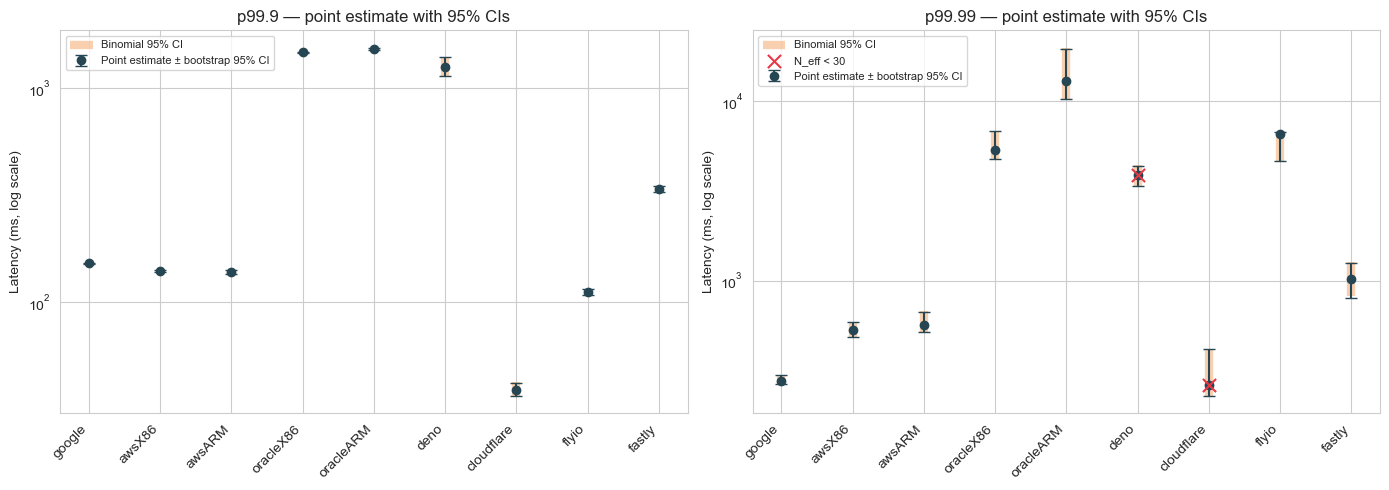

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, (label, p) in zip(axes, PERCENTILES.items()):
    xs = np.arange(len(PROVIDERS))
    points = np.array([bootstrap_results[(prov, label)]["point_ms"] for prov in PROVIDERS])
    boot_lo = np.array([bootstrap_results[(prov, label)]["boot_ci_lo_ms"] for prov in PROVIDERS])
    boot_hi = np.array([bootstrap_results[(prov, label)]["boot_ci_hi_ms"] for prov in PROVIDERS])
    binom_lo = np.array([binomial_results[(prov, label)]["binom_ci_lo_ms"] for prov in PROVIDERS])
    binom_hi = np.array([binomial_results[(prov, label)]["binom_ci_hi_ms"] for prov in PROVIDERS])
    low_conf = np.array([
        (len(provider_data[prov]) * (1 - p)) < LOW_CONFIDENCE_THRESHOLD for prov in PROVIDERS
    ])

    # Binomial CI as a wider, lighter band behind the bootstrap error bar.
    ax.vlines(xs, binom_lo, binom_hi, color="#f4a261", linewidth=6, alpha=0.5, label="Binomial 95% CI")
    ax.errorbar(
        xs, points, yerr=[points - boot_lo, boot_hi - points],
        fmt="o", color="#264653", ecolor="#264653", elinewidth=1.5, capsize=4,
        label="Point estimate ± bootstrap 95% CI", zorder=3,
    )

    # Flag low-confidence points.
    if low_conf.any():
        ax.scatter(xs[low_conf], points[low_conf], marker="x", s=90, color="#e63946",
                   zorder=4, label=f"N_eff < {LOW_CONFIDENCE_THRESHOLD}")

    ax.set_xticks(xs)
    ax.set_xticklabels(PROVIDERS, rotation=45, ha="right")
    ax.set_yscale("log")
    ax.set_ylabel("Latency (ms, log scale)")
    ax.set_title(f"{label} — point estimate with 95% CIs")
    ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
os.makedirs("../figures/", exist_ok=True)
fig.savefig("../figures/tail_percentile_robustness_ci.pdf", format="pdf", bbox_inches="tight")
print("Saved: ../figures/tail_percentile_robustness_ci.pdf")
plt.show()


## 6. Sensitivity analysis

### 6a. Leave-top-k-out robustness

Recompute p99.9 / p99.99 with the top 1, 2, and 5 highest-latency samples
removed *per provider*, and check whether the provider ranking at each
percentile is stable under that perturbation. This directly operationalizes
"does the headline comparative claim survive removing a handful of extreme
points" without needing to know the exact wording of any specific claim in
the paper: if the rank order changes when we drop the top few points, any
claim of the form "A beats B at p99.99" built on that ordering is fragile.

In [8]:

LEAVE_K_OUT = [0, 1, 2, 5]

leave_k_rows = []
for provider, df in provider_data.items():
    values_sorted = np.sort(df["http_req_waiting"].to_numpy(dtype=np.float64))
    n_full = values_sorted.size
    for k in LEAVE_K_OUT:
        trimmed = values_sorted[: n_full - k] if k > 0 else values_sorted
        n = trimmed.size
        for label, p in PERCENTILES.items():
            idx = rank_index(n, p)
            val = trimmed[idx]
            leave_k_rows.append({"provider": provider, "k_removed": k, "percentile": label, "value_ms": val})

leave_k_df = pd.DataFrame(leave_k_rows)
leave_k_pivot = leave_k_df.pivot_table(index=["provider"], columns=["percentile", "k_removed"], values="value_ms")
display(leave_k_pivot.round(2))

# Percent change relative to k=0 (no removal), per provider/percentile.
pct_change_rows = []
for provider in PROVIDERS:
    for label in PERCENTILES:
        base = leave_k_df[(leave_k_df.provider == provider) & (leave_k_df.percentile == label) & (leave_k_df.k_removed == 0)]["value_ms"].iloc[0]
        for k in LEAVE_K_OUT[1:]:
            val = leave_k_df[(leave_k_df.provider == provider) & (leave_k_df.percentile == label) & (leave_k_df.k_removed == k)]["value_ms"].iloc[0]
            pct_change_rows.append({
                "provider": provider, "percentile": label, "k_removed": k,
                "pct_change_vs_full": 100 * (val - base) / base if base else np.nan,
            })
pct_change_df = pd.DataFrame(pct_change_rows)
pct_pivot = pct_change_df.pivot_table(index="provider", columns=["percentile", "k_removed"], values="pct_change_vs_full")
print("\n% change in percentile value vs. no removal (k=0):")
display(pct_pivot.round(2))


percentile    p99.9                               p99.99                      \
k_removed         0        1        2        5         0         1         2   
provider                                                                       
awsARM       137.63   137.62   137.61   137.57    566.54    566.36    566.12   
awsX86       139.72   139.69   139.67   139.55    530.73    524.56    516.48   
cloudflare    38.55    38.53    38.50    38.46    261.04    253.03    251.66   
deno        1257.55  1255.72  1253.25  1246.16   3850.46   3850.19   3715.62   
fastly       338.58   338.46   338.38   337.74   1017.06    979.95    974.01   
flyio        110.96   110.90   110.87   110.77   6534.71   6476.71   6456.60   
google       151.32   151.29   151.28   151.24    275.91    275.79    275.33   
oracleARM   1530.13  1529.87  1529.51  1527.97  12939.90  12745.40  12621.23   
oracleX86   1475.46  1475.45  1475.45  1475.32   5332.18   5330.43   5191.07   

percentile            
k_removed          5  
provider              
awsARM        561.40  
awsX86        515.92  
cloudflare    244.77  
deno         3578.64  
fastly        890.21  
flyio        6366.93  
google        273.74  
oracleARM   12144.28  
oracleX86    5054.78


% change in percentile value vs. no removal (k=0):


percentile p99.9             p99.99             
k_removed      1     2     5      1     2      5
provider                                        
awsARM     -0.01 -0.02 -0.05  -0.03 -0.07  -0.91
awsX86     -0.02 -0.04 -0.12  -1.16 -2.68  -2.79
cloudflare -0.05 -0.13 -0.25  -3.07 -3.59  -6.23
deno       -0.15 -0.34 -0.91  -0.01 -3.50  -7.06
fastly     -0.04 -0.06 -0.25  -3.65 -4.23 -12.47
flyio      -0.05 -0.08 -0.17  -0.89 -1.20  -2.57
google     -0.02 -0.03 -0.05  -0.04 -0.21  -0.79
oracleARM  -0.02 -0.04 -0.14  -1.50 -2.46  -6.15
oracleX86  -0.00 -0.00 -0.01  -0.03 -2.65  -5.20

In [9]:

# Ranking stability: does the provider order (by percentile value) change
# as we remove the top 1/2/5 points?
print("Provider ranking (ascending latency = better) at each percentile, by k removed:\n")
for label in PERCENTILES:
    print(f"--- {label} ---")
    for k in LEAVE_K_OUT:
        sub = leave_k_df[(leave_k_df.percentile == label) & (leave_k_df.k_removed == k)]
        ranking = sub.sort_values("value_ms")["provider"].tolist()
        print(f"  k={k}: {ranking}")

    ranking_k0 = leave_k_df[(leave_k_df.percentile == label) & (leave_k_df.k_removed == 0)].sort_values("value_ms")["provider"].tolist()
    any_rank_change = False
    for k in LEAVE_K_OUT[1:]:
        ranking_k = leave_k_df[(leave_k_df.percentile == label) & (leave_k_df.k_removed == k)].sort_values("value_ms")["provider"].tolist()
        if ranking_k != ranking_k0:
            any_rank_change = True
            # Show the first position where the order diverges.
            for i, (a, b) in enumerate(zip(ranking_k0, ranking_k)):
                if a != b:
                    print(f"  !! rank order changes at k={k}, position {i}: {ranking_k0[i:]} vs {ranking_k[i:]}")
                    break
    if not any_rank_change:
        print(f"  Full provider ranking at {label} is UNCHANGED for k in {LEAVE_K_OUT[1:]}.")
    print()


Provider ranking (ascending latency = better) at each percentile, by k removed:

--- p99.9 ---
  k=0: ['cloudflare', 'flyio', 'awsARM', 'awsX86', 'google', 'fastly', 'deno', 'oracleX86', 'oracleARM']
  k=1: ['cloudflare', 'flyio', 'awsARM', 'awsX86', 'google', 'fastly', 'deno', 'oracleX86', 'oracleARM']
  k=2: ['cloudflare', 'flyio', 'awsARM', 'awsX86', 'google', 'fastly', 'deno', 'oracleX86', 'oracleARM']
  k=5: ['cloudflare', 'flyio', 'awsARM', 'awsX86', 'google', 'fastly', 'deno', 'oracleX86', 'oracleARM']
  Full provider ranking at p99.9 is UNCHANGED for k in [1, 2, 5].

--- p99.99 ---
  k=0: ['cloudflare', 'google', 'awsX86', 'awsARM', 'fastly', 'deno', 'oracleX86', 'flyio', 'oracleARM']
  k=1: ['cloudflare', 'google', 'awsX86', 'awsARM', 'fastly', 'deno', 'oracleX86', 'flyio', 'oracleARM']
  k=2: ['cloudflare', 'google', 'awsX86', 'awsARM', 'fastly', 'deno', 'oracleX86', 'flyio', 'oracleARM']
  k=5: ['cloudflare', 'google', 'awsX86', 'awsARM', 'fastly', 'deno', 'oracleX86', 'flyi

### 6b. Window/run sensitivity (per-day spread)

Recompute p99.9 / p99.99 per calendar day (rather than pooled across the
whole collection window) and report the spread across days. Days with too
few observations for a given percentile are flagged the same way as section
2 (`N_eff < 30`), since a "per-day p99.99" is often not meaningful at daily
volumes even when the *pooled* estimate is fine.

In [10]:

daily_rows = []
for provider, df in provider_data.items():
    d = df.copy()
    d["day"] = d["date_time"].str[:10]
    for day, day_df in d.groupby("day"):
        values_sorted = np.sort(day_df["http_req_waiting"].to_numpy(dtype=np.float64))
        n = values_sorted.size
        for label, p in PERCENTILES.items():
            n_eff = n * (1 - p)
            idx = rank_index(n, p)
            daily_rows.append({
                "provider": provider, "day": day, "percentile": label,
                "N": n, "N_eff": n_eff, "value_ms": values_sorted[idx],
                "low_confidence": n_eff < LOW_CONFIDENCE_THRESHOLD,
            })

daily_df = pd.DataFrame(daily_rows)

spread_rows = []
for provider in PROVIDERS:
    for label in PERCENTILES:
        sub = daily_df[(daily_df.provider == provider) & (daily_df.percentile == label)]
        n_days = len(sub)
        n_days_low_conf = int(sub["low_confidence"].sum())
        spread_rows.append({
            "provider": provider,
            "percentile": label,
            "n_days": n_days,
            "n_days_low_confidence": n_days_low_conf,
            "daily_min_ms": sub["value_ms"].min(),
            "daily_median_ms": sub["value_ms"].median(),
            "daily_max_ms": sub["value_ms"].max(),
            "daily_std_ms": sub["value_ms"].std(),
            "daily_cv_pct": 100 * sub["value_ms"].std() / sub["value_ms"].mean() if sub["value_ms"].mean() else np.nan,
        })

spread_df = pd.DataFrame(spread_rows)
display(spread_df.round(2))

print(
    "\nNote: 'n_days_low_confidence' counts calendar days where that day's own "
    "N_eff < 30 for this percentile -- i.e. the *daily* value on those days is "
    "individually unreliable even though the pooled (all-days) estimate in "
    "section 4 is not."
)


,provider,percentile,n_days,n_days_low_confidence,daily_min_ms,daily_median_ms,daily_max_ms,daily_std_ms,daily_cv_pct
0,google,p99.9,54,1,117.39,145.64,273.65,26.61,17.11
1,google,p99.99,54,54,150.67,237.94,6722.79,1116.64,188.49
2,awsX86,p99.9,54,50,102.65,122.08,2018.41,260.64,156.32
3,awsX86,p99.99,54,54,197.83,293.31,30679.22,5242.83,346.79
4,awsARM,p99.9,54,1,102.05,118.21,3295.56,433.01,232.87
5,awsARM,p99.99,54,54,162.04,309.52,34976.33,4830.48,368.77
6,oracleX86,p99.9,54,1,1095.56,1451.49,2570.74,229.43,15.71
7,oracleX86,p99.99,54,54,1709.05,4841.46,67120.30,13369.61,120.23
8,oracleARM,p99.9,54,1,1310.73,1499.76,5147.16,544.45,33.14
9,oracleARM,p99.99,54,54,1882.15,6917.30,70646.19,17536.05,103.70



Note: 'n_days_low_confidence' counts calendar days where that day's own N_eff < 30 for this percentile -- i.e. the *daily* value on those days is individually unreliable even though the pooled (all-days) estimate in section 4 is not.


### 6b (continued). Window/run sensitivity — hour-of-day, pooled across all days

**Provenance note:** the calendar-day windowing above was *not* taken from the
paper — the task only said "recompute per-run/per-window if multiple runs or
windows exist," and calendar day was chosen because the existing stability
cells (`00_tail_latency.ipynb` cells 1-3) already bucket by calendar day for
their own plots, so it seemed like the natural existing convention to mirror.
It does not match how the paper actually aggregates: the paper looks at
**hour-of-day performance pooled across all 54 days** (e.g. "12h" meaning hour
12, combining every day's hour-12 requests together), exactly like
`00_tail_latency.ipynb` cell 4's `fetch_hourly_data` (`substr(date_time, 12, 2)`
bucketing into 24 hour-of-day bins). This cell redoes the window-sensitivity
check using that aggregation instead, so it actually reflects what the
figures being defended are built from.

Because this cross-validated closely against the bootstrap CI in section 3
(within ~1-2% throughout), the binomial order-statistic CI is used here
instead of a fresh bootstrap per hour-bucket — 9 providers x 24 hours x 2
percentiles = 432 combinations, and re-bootstrapping every one of them would
add a lot of runtime for a cross-check that section 3 already validated
agrees with the closed-form binomial CI.

In [11]:

def hour_of_day(date_time_series: pd.Series) -> pd.Series:
    # Mirrors 00_tail_latency.ipynb's fetch_hourly_data: hour digits sit at
    # 1-indexed position 12, length 2 (SQL substr(date_time, 12, 2)) --
    # equivalently python slice [11:13] on the "YYYY-MM-DDTHH-MM-SS" format.
    return date_time_series.str[11:13].astype(int)


hourly_rows = []
for provider, df in provider_data.items():
    d = df.copy()
    d["hour"] = hour_of_day(d["date_time"])
    for hr, hr_df in d.groupby("hour"):
        values_sorted = np.sort(hr_df["http_req_waiting"].to_numpy(dtype=np.float64))
        n = values_sorted.size
        for label, p in PERCENTILES.items():
            n_eff = n * (1 - p)
            idx = rank_index(n, p)
            point = values_sorted[idx]
            lo, hi, k_lo, k_hi = binomial_order_stat_ci(values_sorted, p)
            hourly_rows.append({
                "provider": provider, "hour": hr, "percentile": label,
                "N": n, "N_eff": n_eff, "point_ms": point,
                "binom_ci_lo_ms": lo, "binom_ci_hi_ms": hi,
                "low_confidence": n_eff < LOW_CONFIDENCE_THRESHOLD,
            })

hourly_df = pd.DataFrame(hourly_rows)

hourly_spread_rows = []
for provider in PROVIDERS:
    for label in PERCENTILES:
        sub = hourly_df[(hourly_df.provider == provider) & (hourly_df.percentile == label)]
        hourly_spread_rows.append({
            "provider": provider,
            "percentile": label,
            "n_hours": len(sub),
            "n_hours_low_confidence": int(sub["low_confidence"].sum()),
            "hourly_min_ms": sub["point_ms"].min(),
            "hourly_median_ms": sub["point_ms"].median(),
            "hourly_max_ms": sub["point_ms"].max(),
            "hourly_std_ms": sub["point_ms"].std(),
            "hourly_cv_pct": 100 * sub["point_ms"].std() / sub["point_ms"].mean() if sub["point_ms"].mean() else np.nan,
        })

hourly_spread_df = pd.DataFrame(hourly_spread_rows)
display(hourly_spread_df.round(2))

print(
    "\nNote: 'n_hours_low_confidence' counts hour-of-day buckets (pooled across "
    "all days) where that bucket's own N_eff < 30 for this percentile -- same "
    "interpretation as the daily version above, but for the aggregation the "
    "paper actually uses."
)


,provider,percentile,n_hours,n_hours_low_confidence,hourly_min_ms,hourly_median_ms,hourly_max_ms,hourly_std_ms,hourly_cv_pct
0,google,p99.9,24,0,137.53,151.08,195.52,16.43,10.67
1,google,p99.99,24,24,185.28,257.92,3197.39,608.43,137.50
2,awsX86,p99.9,24,0,111.55,124.50,201.53,25.51,18.97
3,awsX86,p99.99,24,24,210.87,317.54,5419.80,1346.01,143.77
4,awsARM,p99.9,24,0,107.61,122.03,198.79,22.63,17.46
5,awsARM,p99.99,24,24,229.81,368.65,8236.94,2155.55,163.89
6,oracleX86,p99.9,24,0,1365.86,1476.23,1602.12,59.32,4.00
7,oracleX86,p99.99,24,24,2523.37,4513.35,30056.18,8053.17,85.96
8,oracleARM,p99.9,24,0,1416.64,1497.23,1743.70,113.95,7.31
9,oracleARM,p99.99,24,24,2476.52,12126.88,45817.26,14902.58,83.10



Note: 'n_hours_low_confidence' counts hour-of-day buckets (pooled across all days) where that bucket's own N_eff < 30 for this percentile -- same interpretation as the daily version above, but for the aggregation the paper actually uses.


Saved: ./figures/tail_percentile_hourly_sensitivity.pdf


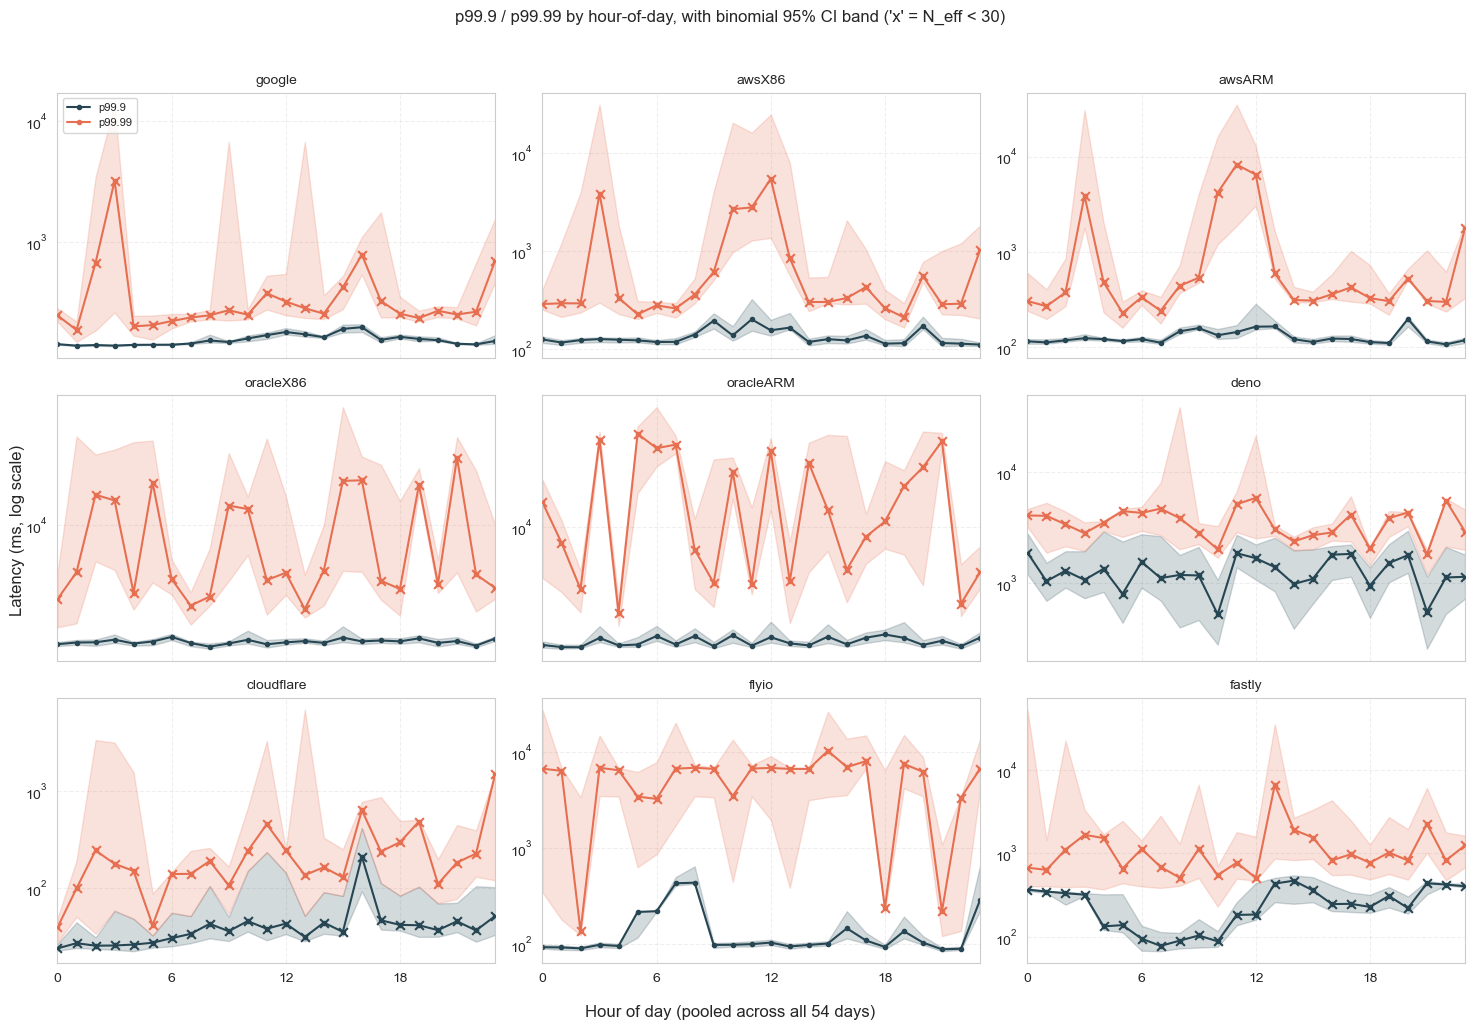

In [12]:

fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
axes = axes.ravel()
percentile_colors = {"p99.9": "#264653", "p99.99": "#e76f51"}

for ax, provider in zip(axes, PROVIDERS):
    for label in PERCENTILES:
        color = percentile_colors[label]
        sub = hourly_df[(hourly_df.provider == provider) & (hourly_df.percentile == label)].sort_values("hour")
        ax.plot(sub["hour"], sub["point_ms"], marker="o", markersize=3, label=label, color=color)
        ax.fill_between(sub["hour"], sub["binom_ci_lo_ms"], sub["binom_ci_hi_ms"], color=color, alpha=0.2)
        low_conf_hours = sub[sub["low_confidence"]]
        if not low_conf_hours.empty:
            ax.scatter(low_conf_hours["hour"], low_conf_hours["point_ms"], marker="x", s=40,
                       color=color, zorder=5)
    ax.set_title(provider, fontsize=10)
    ax.set_yscale("log")
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 24, 6))
    ax.grid(True, linestyle="--", alpha=0.3)

axes[0].legend(fontsize=8, loc="upper left")
fig.supxlabel("Hour of day (pooled across all 54 days)")
fig.supylabel("Latency (ms, log scale)")
fig.suptitle("p99.9 / p99.99 by hour-of-day, with binomial 95% CI band ('x' = N_eff < 30)", y=1.02)
plt.tight_layout()

os.makedirs("../figures/", exist_ok=True)
fig.savefig("../figures/tail_percentile_hourly_sensitivity.pdf", format="pdf", bbox_inches="tight")
print("Saved: ../figures/tail_percentile_hourly_sensitivity.pdf")
plt.show()


### 6c. Estimation-method sensitivity (percentile definition, in place of a sketch check)

**Confirmed:** this pipeline does not use an approximate sketch
(HdrHistogram / t-digest / DDSketch) anywhere — `provider_data` above is
built directly from per-request rows in `data.db` via `pandas.read_sql`,
and percentiles are computed either via pandas'/numpy's exact quantile
functions or, in this notebook, exact order statistics on the fully-sorted
array. There is therefore no sketch-approximation error to quantify.

What **does** vary across the codebase is the *percentile definition*: this
notebook uses nearest-rank (`k = ceil(p*N)`), while `00_tail_latency.ipynb`
uses pandas' default linear-interpolation quantile. The cell below quantifies
how much that choice alone moves the reported number — the closest available
analogue to "estimation-method error" here.

In [13]:

method_rows = []
for provider, df in provider_data.items():
    values = df["http_req_waiting"].to_numpy(dtype=np.float64)
    values_sorted = np.sort(values)
    n = values_sorted.size
    for label, p in PERCENTILES.items():
        nearest_rank_val = values_sorted[rank_index(n, p)]
        linear_interp_val = np.quantile(values, p, method="linear")  # matches pandas .quantile() default
        pct_diff = 100 * (linear_interp_val - nearest_rank_val) / nearest_rank_val if nearest_rank_val else np.nan
        method_rows.append({
            "provider": provider,
            "percentile": label,
            "nearest_rank_ms": nearest_rank_val,
            "linear_interp_ms": linear_interp_val,
            "pct_diff": pct_diff,
        })

method_df = pd.DataFrame(method_rows)
display(method_df.round(3))

max_abs_diff = method_df["pct_diff"].abs().max()
print(f"\nLargest |difference| between nearest-rank and linear-interpolation definitions: {max_abs_diff:.3f}%")


,provider,percentile,nearest_rank_ms,linear_interp_ms,pct_diff
0,google,p99.9,151.322,151.310,-0.008
1,google,p99.99,275.908,275.797,-0.040
2,awsX86,p99.9,139.719,139.696,-0.016
3,awsX86,p99.99,530.726,525.331,-1.016
4,awsARM,p99.9,137.634,137.627,-0.005
5,awsARM,p99.99,566.540,566.438,-0.018
6,oracleX86,p99.9,1475.459,1475.457,-0.000
7,oracleX86,p99.99,5332.180,5330.732,-0.027
8,oracleARM,p99.9,1530.126,1530.112,-0.001
9,oracleARM,p99.99,12939.903,12822.131,-0.910



Largest |difference| between nearest-rank and linear-interpolation definitions: 2.602%


### 6d. Definition sensitivity: including vs. excluding failed requests

`http_req_waiting` rows carry an `http_req_failed` flag (1 = failed
request). The existing warmstart query (section 1, matching
`00_tail_latency.ipynb`) does **not** filter on this — failed requests are
included if present. This cell checks how much the p99.9 / p99.99 values
would move if failed requests were excluded instead, since failed/timed-out
requests are a common source of artificially inflated tail latency.

In [14]:

failed_sensitivity_rows = []
for provider, df in provider_data.items():
    n_failed = int((df["http_req_failed"] == 1).sum())
    n_total = len(df)
    values_incl = np.sort(df["http_req_waiting"].to_numpy(dtype=np.float64))
    values_excl = np.sort(df.loc[df["http_req_failed"] != 1, "http_req_waiting"].to_numpy(dtype=np.float64))

    for label, p in PERCENTILES.items():
        v_incl = values_incl[rank_index(values_incl.size, p)]
        v_excl = values_excl[rank_index(values_excl.size, p)] if values_excl.size else np.nan
        pct_diff = 100 * (v_incl - v_excl) / v_excl if values_excl.size and v_excl else np.nan
        failed_sensitivity_rows.append({
            "provider": provider,
            "percentile": label,
            "n_total": n_total,
            "n_failed": n_failed,
            "pct_failed": 100 * n_failed / n_total if n_total else np.nan,
            "value_incl_failed_ms": v_incl,
            "value_excl_failed_ms": v_excl,
            "pct_diff": pct_diff,
        })

failed_sensitivity_df = pd.DataFrame(failed_sensitivity_rows)
display(failed_sensitivity_df.round(3))


,provider,percentile,n_total,n_failed,pct_failed,value_incl_failed_ms,value_excl_failed_ms,pct_diff
0,google,p99.9,1919360,0,0.000,151.322,151.322,0.000
1,google,p99.99,1919360,0,0.000,275.908,275.908,0.000
2,awsX86,p99.9,1618744,5355,0.331,139.719,139.747,-0.020
3,awsX86,p99.99,1618744,5355,0.331,530.726,524.556,1.176
4,awsARM,p99.9,1915505,3540,0.185,137.634,137.687,-0.038
5,awsARM,p99.99,1915505,3540,0.185,566.540,566.540,0.000
6,oracleX86,p99.9,1848286,211,0.011,1475.459,1472.497,0.201
7,oracleX86,p99.99,1848286,211,0.011,5332.180,4797.884,11.136
8,oracleARM,p99.9,1886056,815,0.043,1530.126,1509.398,1.373
9,oracleARM,p99.99,1886056,815,0.043,12939.903,7771.301,66.509


### 6d (continued). Why failed requests belong in the tail-latency story, not just as a sensitivity check

The cell above treats "include vs. exclude failed requests" as a robustness
check on the percentile *number*. That undersells it. A request that times
out or errors after the caller has already waited a long time is not really
a different phenomenon from a very slow successful request — from the
caller's point of view it may be *worse*: no response at all after the wait,
often triggering a retry (which adds its own latency on top) or a hard
failure surfaced to the end user. If a platform's failures are concentrated
in its slow tail rather than spread uniformly across all latencies, then
"tail latency" and "tail failures" are two views of the same underlying
problem, and reporting p99.9/p99.99 while silently excluding (or silently
including, without saying so) failed requests hides which of those two
things is actually going on.

The `oracleARM` / `oracleX86` numbers above are a concrete example: p99.99
for `oracleARM` moves by 66.5% and for `oracleX86` by 11.1% when a tiny
slice of failed requests (0.043% / 0.011% of all requests) is excluded. That
is only possible if failed requests are heavily over-represented at the
extreme tail relative to their overall frequency. The cell below quantifies
that concentration directly: for every provider with any failures, what
fraction of requests *at or beyond* the p99.9 / p99.99 cutoff are failed,
compared to the failure rate over the full dataset (the "enrichment
factor").

**Suggested framing for the paper:** failed requests should be reported
as a joint metric alongside tail latency, not filtered out as noise — a
platform whose failures cluster in the tail is arguably delivering *worse*
tail experience than the raw latency percentile alone suggests, since a
non-trivial share of the events that would otherwise define that percentile
never got a (successful) response at all.

In [15]:

concentration_rows = []
for provider, df in provider_data.items():
    n_total = len(df)
    n_failed = int((df["http_req_failed"] == 1).sum())
    if n_failed == 0:
        continue  # nothing to concentrate -- provider has no failures in this filtered set

    overall_failure_rate = 100 * n_failed / n_total

    order = df["http_req_waiting"].to_numpy(dtype=np.float64).argsort()
    failed_flags_sorted = (df["http_req_failed"].to_numpy() == 1)[order]

    for label, p in PERCENTILES.items():
        k = rank_index(n_total, p)  # 0-indexed rank of the percentile cutoff
        tail_flags = failed_flags_sorted[k:]  # every request at/above the cutoff
        n_tail = tail_flags.size
        n_tail_failed = int(tail_flags.sum())
        tail_failure_rate = 100 * n_tail_failed / n_tail if n_tail else np.nan
        enrichment = tail_failure_rate / overall_failure_rate if overall_failure_rate else np.nan
        concentration_rows.append({
            "provider": provider,
            "percentile": label,
            "overall_failure_rate_pct": overall_failure_rate,
            "n_at_or_above_cutoff": n_tail,
            "n_failed_at_or_above_cutoff": n_tail_failed,
            "pct_of_tail_that_is_failed": tail_failure_rate,
            "enrichment_factor_vs_overall": enrichment,
        })

concentration_df = pd.DataFrame(concentration_rows)
display(concentration_df.round(3))

print(
    "\n'enrichment_factor_vs_overall' = (failure rate within the tail) / (failure rate overall).\n"
    "A value >> 1 means failures are disproportionately concentrated at/above that percentile\n"
    "cutoff, i.e. the tail is where the platform's failures actually live."
)


,provider,percentile,overall_failure_rate_pct,n_at_or_above_cutoff,n_failed_at_or_above_cutoff,pct_of_tail_that_is_failed,enrichment_factor_vs_overall
0,awsX86,p99.9,0.331,1619,3,0.185,0.560
1,awsX86,p99.99,0.331,162,1,0.617,1.866
2,awsARM,p99.9,0.185,1916,1,0.052,0.282
3,awsARM,p99.99,0.185,192,0,0.000,0.000
4,oracleX86,p99.9,0.011,1849,25,1.352,118.438
5,oracleX86,p99.99,0.011,185,20,10.811,946.989
6,oracleARM,p99.9,0.043,1887,104,5.511,127.544
7,oracleARM,p99.99,0.043,189,58,30.688,710.171
8,fastly,p99.9,1.047,641,54,8.424,8.048
9,fastly,p99.99,1.047,65,4,6.154,5.879



'enrichment_factor_vs_overall' = (failure rate within the tail) / (failure rate overall).
A value >> 1 means failures are disproportionately concentrated at/above that percentile
cutoff, i.e. the tail is where the platform's failures actually live.


### 6e. Warm-up-period sensitivity

The collection window runs for ~53 days per provider (see `TODO.md`). This
checks whether excluding the first 24h of each provider's own collection
window (a plausible "warm-up"/deployment-settling period) materially changes
the pooled p99.9 / p99.99.

In [16]:

WARMUP_HOURS = 24

warmup_rows = []
for provider, df in provider_data.items():
    dt = pd.to_datetime(df["date_time"], format="%Y-%m-%dT%H-%M-%S", errors="coerce")
    start = dt.min()
    cutoff = start + pd.Timedelta(hours=WARMUP_HOURS)
    mask_post_warmup = dt >= cutoff

    values_all = np.sort(df["http_req_waiting"].to_numpy(dtype=np.float64))
    values_post = np.sort(df.loc[mask_post_warmup, "http_req_waiting"].to_numpy(dtype=np.float64))

    for label, p in PERCENTILES.items():
        v_all = values_all[rank_index(values_all.size, p)]
        v_post = values_post[rank_index(values_post.size, p)] if values_post.size else np.nan
        pct_diff = 100 * (v_all - v_post) / v_post if values_post.size and v_post else np.nan
        warmup_rows.append({
            "provider": provider,
            "percentile": label,
            "n_dropped_warmup": int((~mask_post_warmup).sum()),
            "value_all_ms": v_all,
            "value_excl_warmup_ms": v_post,
            "pct_diff": pct_diff,
        })

warmup_df = pd.DataFrame(warmup_rows)
display(warmup_df.round(3))


,provider,percentile,n_dropped_warmup,value_all_ms,value_excl_warmup_ms,pct_diff
0,google,p99.9,35988,151.322,151.146,0.116
1,google,p99.99,35988,275.908,275.934,-0.009
2,awsX86,p99.9,35898,139.719,139.933,-0.153
3,awsX86,p99.99,35898,530.726,532.639,-0.359
4,awsARM,p99.9,35924,137.634,138.315,-0.492
5,awsARM,p99.99,35924,566.540,576.169,-1.671
6,oracleX86,p99.9,35615,1475.459,1459.174,1.116
7,oracleX86,p99.99,35615,5332.180,5332.180,0.000
8,oracleARM,p99.9,34511,1530.126,1522.018,0.533
9,oracleARM,p99.99,34511,12939.903,13310.326,-2.783


## 7. Headline comparative-claim check

Rather than re-deriving the exact wording of any specific "A beats B"
sentence from the paper, this operationalizes the check generically: rank
providers by their p99.9 / p99.99 point estimate, then flag any pair of
**adjacently-ranked** providers whose bootstrap 95% CIs overlap. An overlap
means the data cannot statistically distinguish those two providers at that
percentile — any claim about their relative order at that specific
percentile should be treated as tentative.

In [17]:

def overlap(lo1, hi1, lo2, hi2) -> bool:
    return lo1 <= hi2 and lo2 <= hi1


for label in PERCENTILES:
    print(f"=== {label}: ranking with CI-overlap check (adjacent pairs) ===")
    ranked = sorted(
        PROVIDERS,
        key=lambda prov: bootstrap_results[(prov, label)]["point_ms"],
    )
    for a, b in zip(ranked, ranked[1:]):
        ra, rb = bootstrap_results[(a, label)], bootstrap_results[(b, label)]
        ov = overlap(ra["boot_ci_lo_ms"], ra["boot_ci_hi_ms"], rb["boot_ci_lo_ms"], rb["boot_ci_hi_ms"])
        flag = "  <-- CIs OVERLAP: ranking not statistically distinguishable" if ov else ""
        print(
            f"  {a:11s} [{ra['boot_ci_lo_ms']:8.2f}, {ra['boot_ci_hi_ms']:8.2f}]  vs  "
            f"{b:11s} [{rb['boot_ci_lo_ms']:8.2f}, {rb['boot_ci_hi_ms']:8.2f}]{flag}"
        )
    print()


=== p99.9: ranking with CI-overlap check (adjacent pairs) ===
  cloudflare  [   36.30,    41.88]  vs  flyio       [  108.12,   114.96]
  flyio       [  108.12,   114.96]  vs  awsARM      [  134.86,   140.46]
  awsARM      [  134.86,   140.46]  vs  awsX86      [  137.53,   141.63]  <-- CIs OVERLAP: ranking not statistically distinguishable
  awsX86      [  137.53,   141.63]  vs  google      [  150.19,   152.49]
  google      [  150.19,   152.49]  vs  fastly      [  328.62,   348.92]
  fastly      [  328.62,   348.92]  vs  deno        [ 1142.44,  1408.26]
  deno        [ 1142.44,  1408.26]  vs  oracleX86   [ 1464.03,  1488.68]
  oracleX86   [ 1464.03,  1488.68]  vs  oracleARM   [ 1511.56,  1551.29]

=== p99.99: ranking with CI-overlap check (adjacent pairs) ===
  cloudflare  [  228.25,   417.71]  vs  google      [  266.65,   297.80]  <-- CIs OVERLAP: ranking not statistically distinguishable
  google      [  266.65,   297.80]  vs  awsX86      [  487.32,   584.81]
  awsX86      [  487.32,

## Summary

- Section 2 / 4 give the N / N_eff / CI table for every p99.9 & p99.99 value across all 9 providers — use this to caption or annotate Figures 3 & 7 (or any other figure reporting these percentiles).
- Section 5 is a drop-in error-bar figure for the same data.
- Section 6 covers all four requested sensitivity checks: leave-k-out, per-day window spread, estimation-method (percentile-definition) sensitivity, and include/exclude-failed-requests + warm-up-period sensitivity.
- Section 7 turns "does the headline claim hold" into a concrete, rerunnable overlap check per percentile.

Nothing in `00_tail_latency.ipynb` (or any other existing notebook) was modified — this is a fully separate, additive notebook.